# Modelado de uplift — Criteo (2018) — incrementalidad de publicidad display
Fases 3 a 6 de CRISP-DM: preparación, modelado (meta-learners S/T/X), evaluación (Qini, AUUC, IPW) y despliegue (API, dashboard, drift).

Con `RUN = True` se re-ejecuta el pipeline completo para `criteo`.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]
import numpy as np, pandas as pd
from IPython.display import Image, display
from uplift.dataset import load_config
pd.set_option("display.float_format", "{:.4f}".format)
cfg = load_config("criteo")
FIG = cfg.figures_dir
def show(name):
    p = FIG / f"{name}.png"
    if p.exists():
        display(Image(str(p)))
RUN = not cfg.bundle_path.exists()
print(cfg.modeling)

{'sample_size': 2000000, 'test_size': 0.3, 'cv_folds': 3, 'cv_repeats': 1, 'n_boot': 100, 'n_jobs': -1}


## 1. Entrenamiento y selección por validación cruzada

Filas: {'total': 13979592, 'train': 1400000, 'test': 600000}


outcome,conversion,visit
learner,,
baseline,0.3979,0.3399
s_learner_lgbm,0.3948,0.3525
s_learner_linear,0.3296,0.3700
t_learner_lgbm,0.3849,0.3271
t_learner_linear,0.3470,0.3940
x_learner_lgbm,0.3216,0.3622
x_learner_linear,0.3686,0.3525


Seleccionados: {'conversion': 's_learner_lgbm', 'visit': 't_learner_linear'}


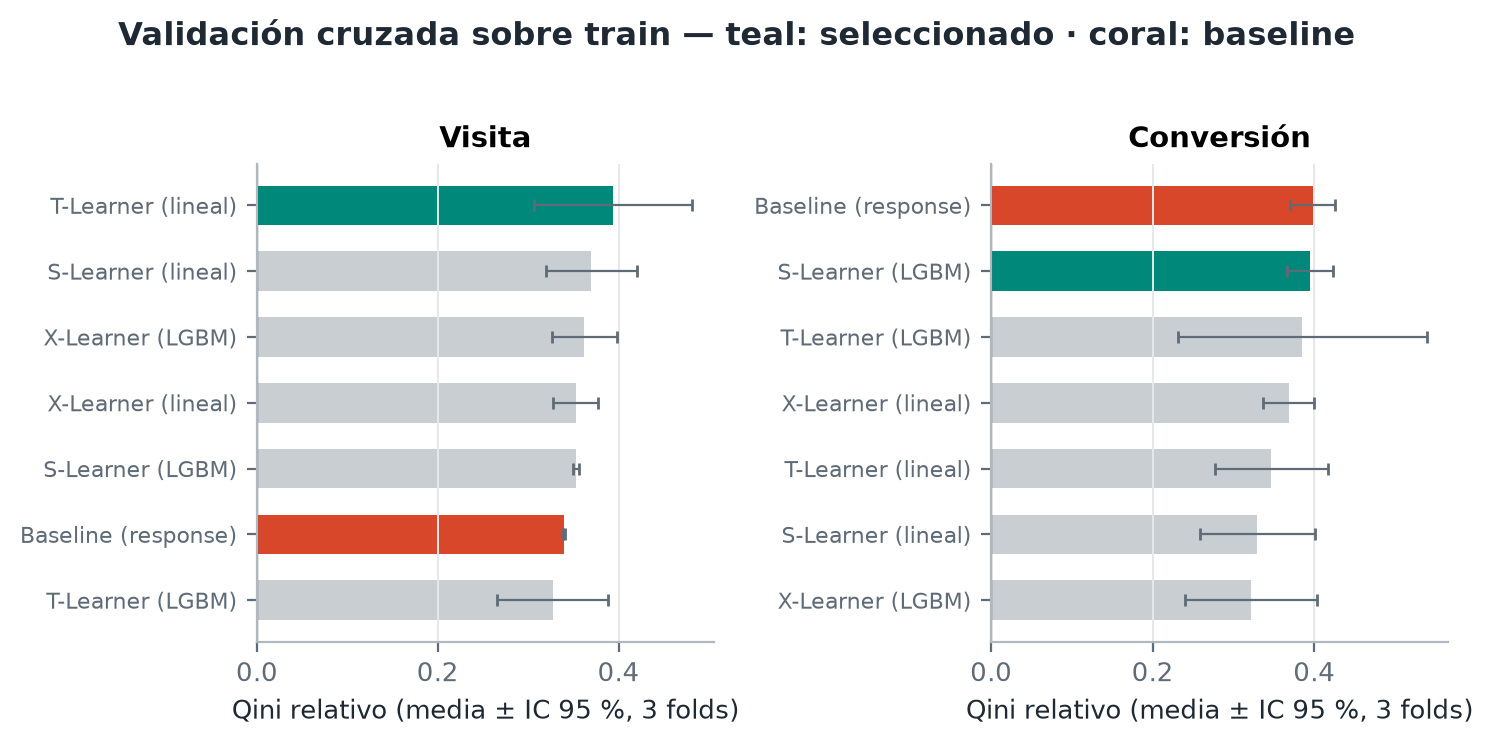

In [2]:
if RUN:
    from uplift import train
    train.run(cfg)
metrics = json.load(open(cfg.reports_dir / 'metrics.json'))
print('Filas:', metrics.get('n_rows'))
cv = pd.DataFrame(metrics['cv_summary'])
display(cv.pivot(index='learner', columns='outcome', values='mean'))
print('Seleccionados:', metrics['selected'])
show('cv_model_selection')

## 2. Evaluación en test

auuc qini_relative uplift_at_10
treatment                      ads           ads          ads
outcome    learner                                           
conversion baseline         0.0065        0.4357       0.0093
           s_learner_lgbm   0.0065        0.4362       0.0095
           s_learner_linear 0.0060        0.4056       0.0094
           t_learner_lgbm   0.0053        0.3527       0.0088
           t_learner_linear 0.0073        0.4872       0.0107
           x_learner_lgbm   0.0061        0.4102       0.0096
           x_learner_linear 0.0064        0.4309       0.0098
visit      baseline         0.0352        0.3634       0.0589
           s_learner_lgbm   0.0363        0.3754       0.0598
           s_learner_linear 0.0338        0.3504       0.0616
           t_learner_lgbm   0.0302        0.3133       0.0631
           t_learner_linear 0.0318        0.3302       0.0642
           x_learner_lgbm   0.0330        0.3423       0.0606
           x_learner_linear 0.0342        0.3553       0.0603

visit      ads     baseline           Qini rel=0.363 IC95%=[0.342 0.389]
visit      ads     t_learner_linear   Qini rel=0.330 IC95%=[0.27  0.393]
conversion ads     baseline           Qini rel=0.436 IC95%=[0.4   0.473]
conversion ads     s_learner_lgbm     Qini rel=0.436 IC95%=[0.404 0.471]


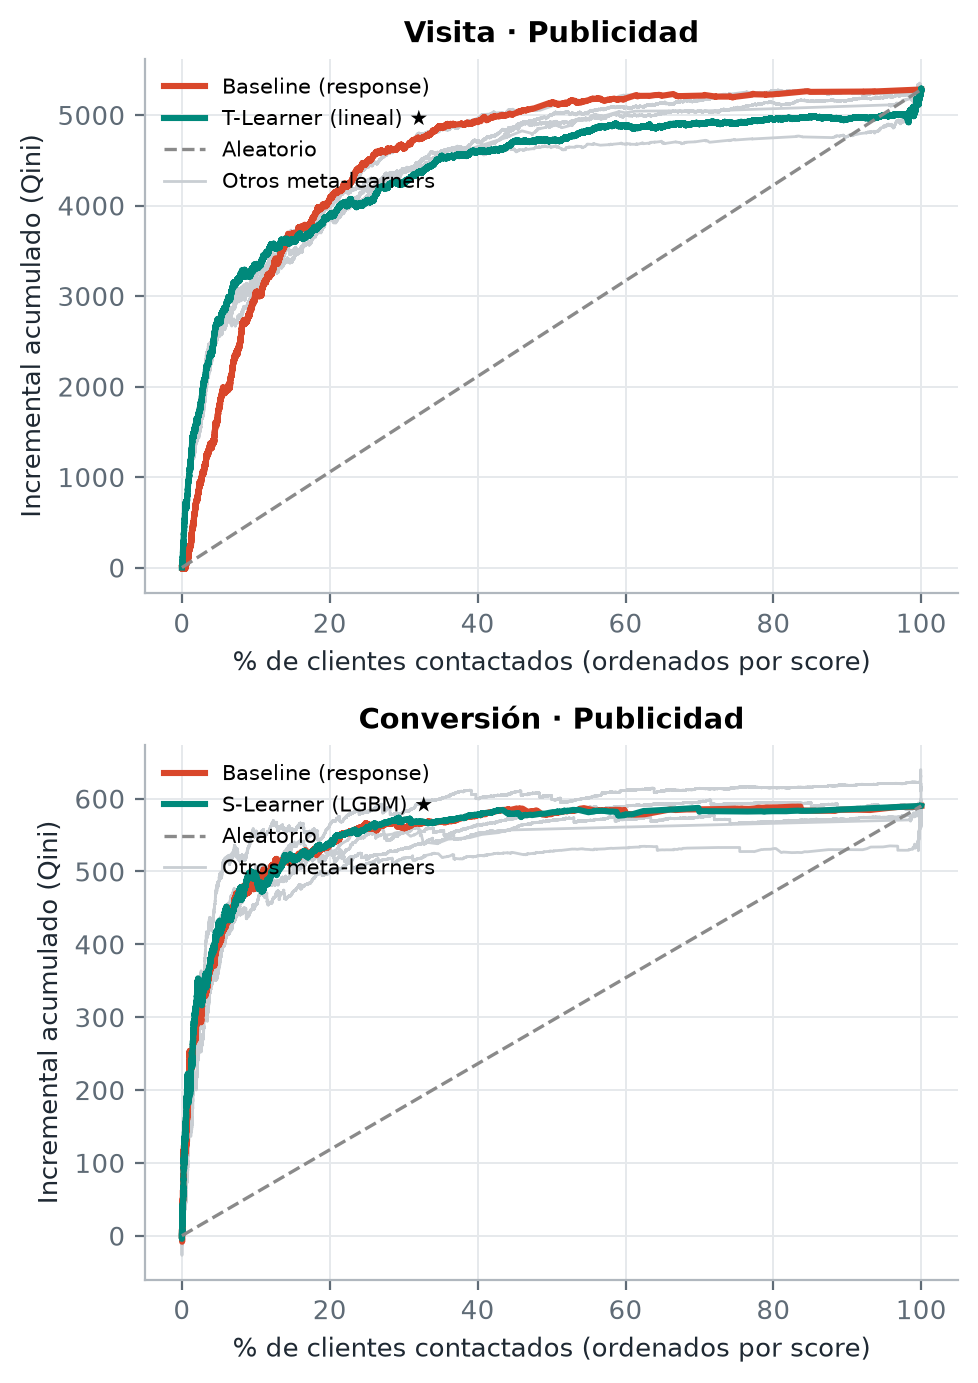

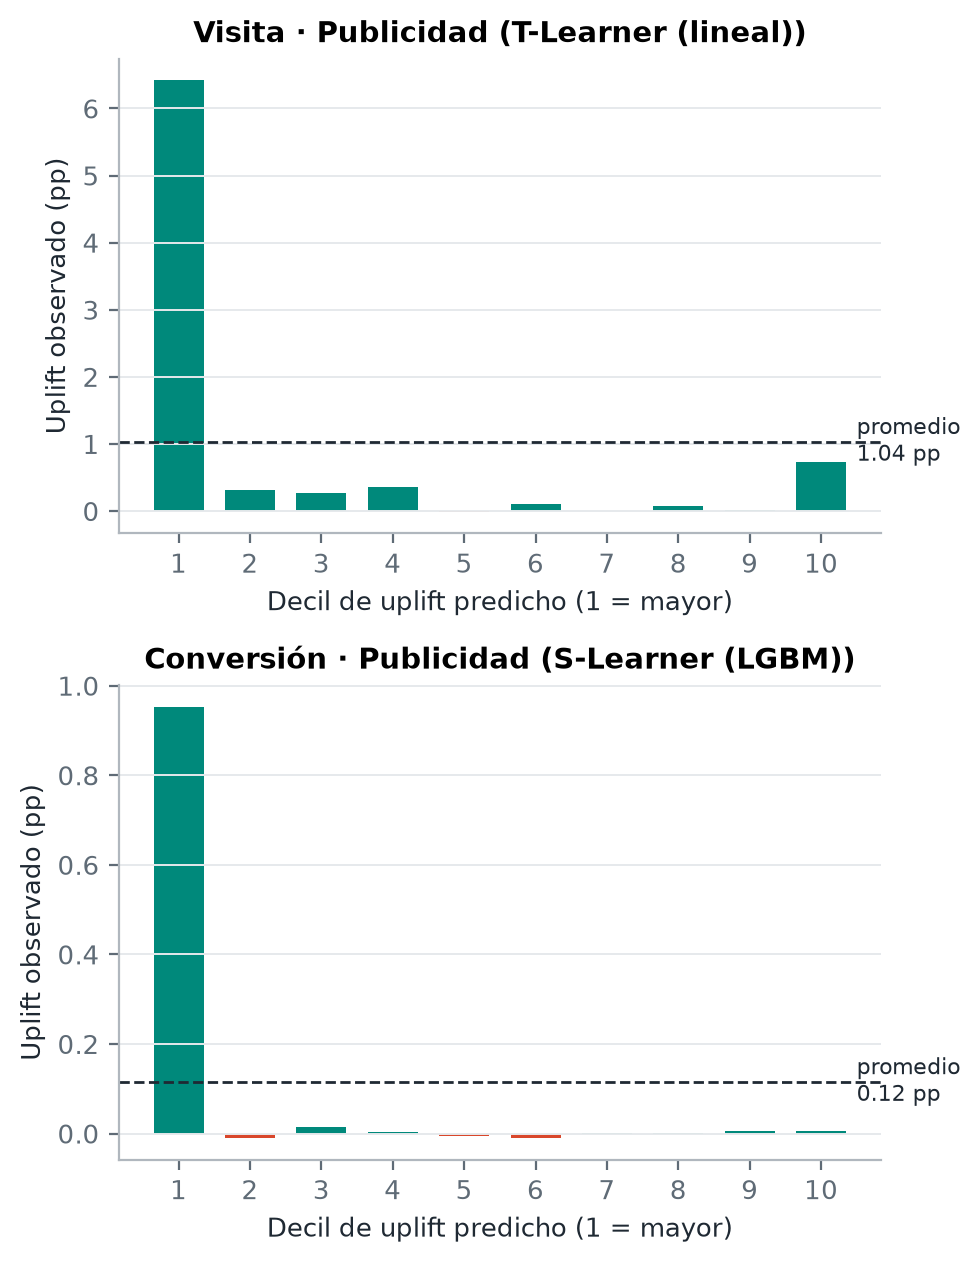

In [3]:
tm = pd.read_csv(cfg.tables_dir / 'test_metrics.csv')
display(tm.pivot_table(index=['outcome','learner'], columns='treatment', values=['qini_relative','auuc','uplift_at_10']))
for o, v in metrics['results'].items():
    sel = metrics['selected'][o]
    for a in [t.label for t in cfg.treatments]:
        for key in ('baseline', sel):
            print(f"{o:10s} {a:7s} {key:18s} Qini rel={v[key][a]['qini_relative']:.3f} IC95%={np.round(v[key][a]['qini_relative_ci95'], 3)}")
show('qini_curves')
show('uplift_by_decile')

## 3. Interpretación del CATE

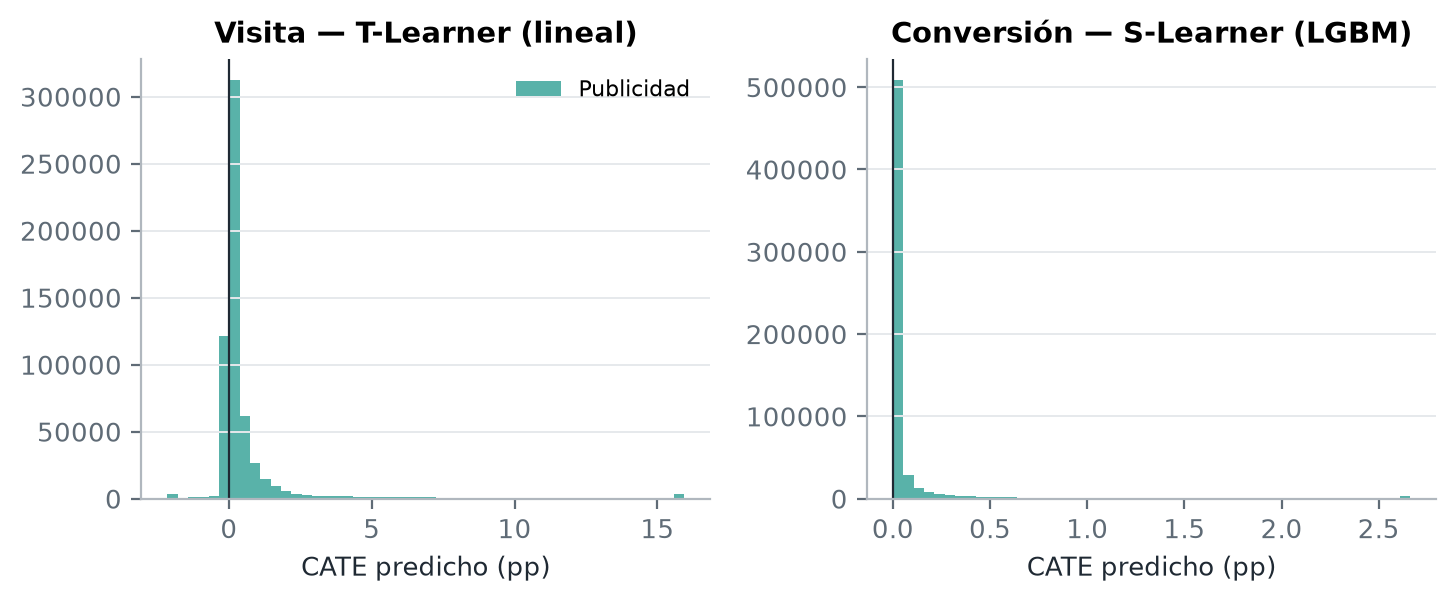

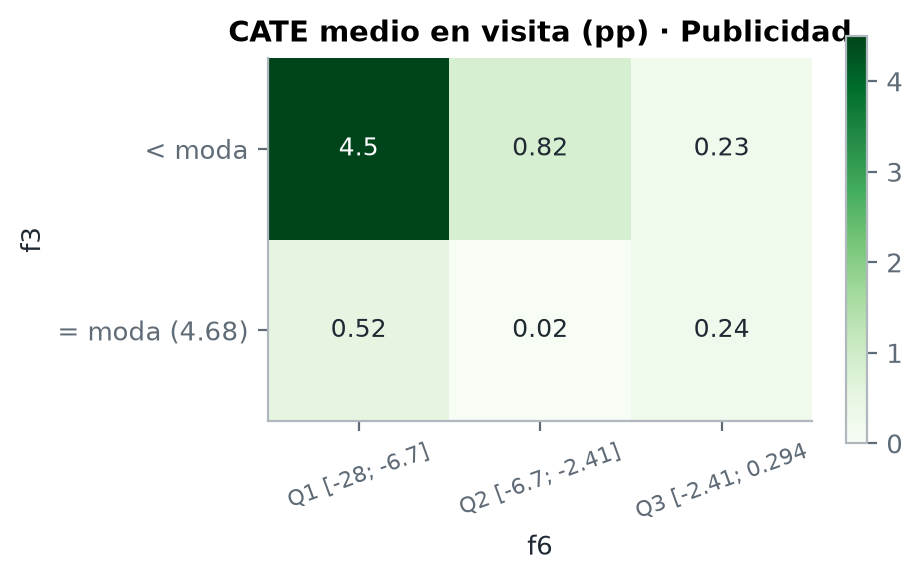

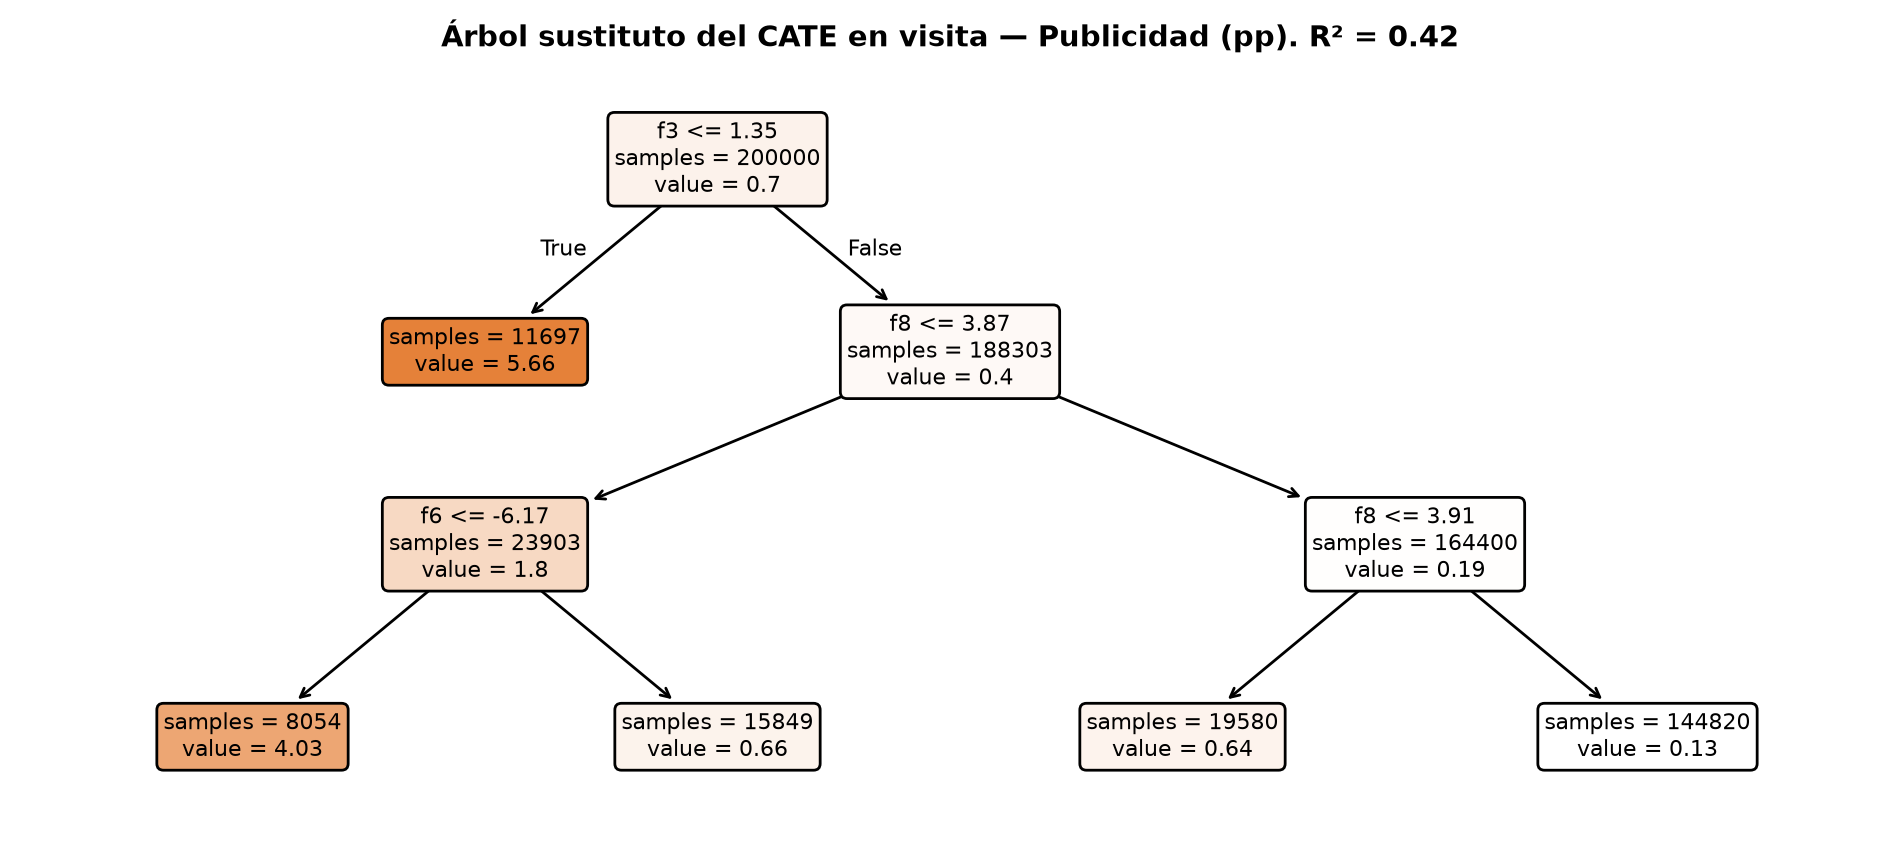

In [4]:
if RUN or not (FIG / 'surrogate_tree.png').exists():
    from uplift import figures
    figures.run(cfg)
show('cate_distribution')
show('cate_segments')
show('surrogate_tree')

## 4. Política bajo presupuesto (IPW, con IC 95 %)

,policy,share_contacted,share_ads,inc_visit_per_1000,inc_visit_lo,inc_visit_hi,inc_conversion_per_1000,inc_conversion_lo,inc_conversion_hi,cost_per_1000,profit_per_1000,profit_lo,profit_hi,roi
0,No enviar,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN
1,Enviar a todos — Publicidad,1.0000,1.0000,10.3569,8.9543,11.7594,1.1569,0.8316,1.4821,5.0000,18.1373,11.6322,24.6423,3.6275
2,Aleatoria (50%),0.5000,0.5000,4.9307,3.9330,5.9285,0.5307,0.3027,0.7587,2.5000,8.1144,3.5546,12.6742,3.2458
3,Modelo (50%),0.5000,0.5000,10.2817,8.8885,11.6749,1.1529,0.8303,1.4756,2.5000,20.5588,14.1064,27.0113,8.2235
4,"Modelo (sin restricción, uplift>0)",1.0000,1.0000,10.3569,8.9543,11.7594,1.1569,0.8316,1.4821,5.0000,18.1373,11.6322,24.6423,3.6275


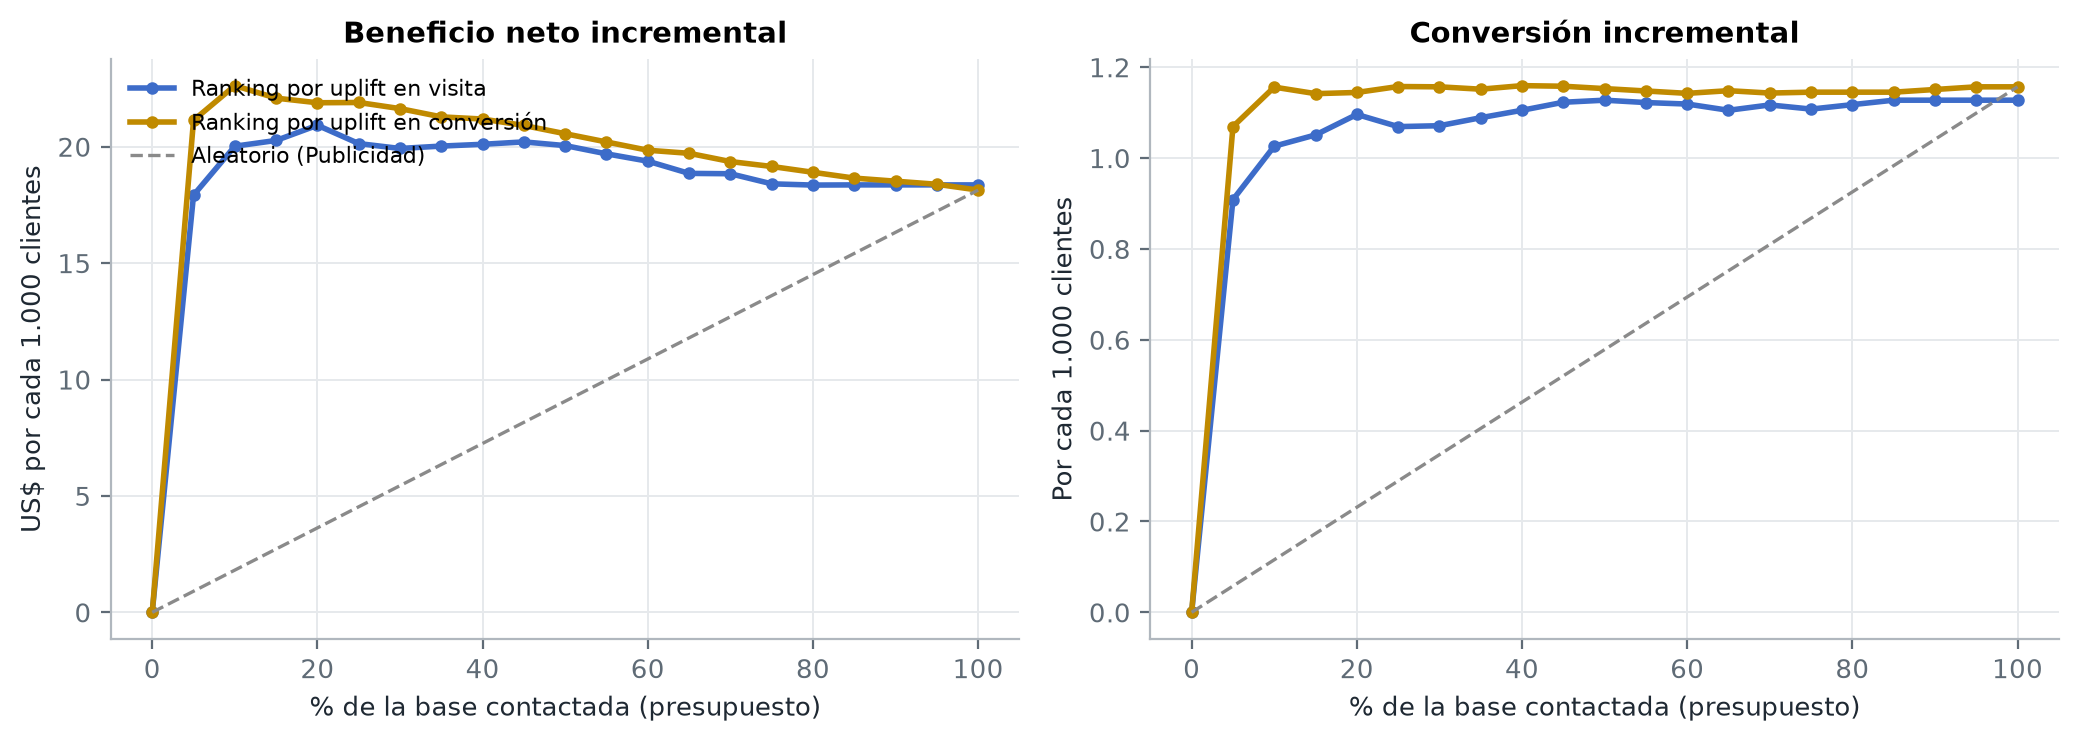

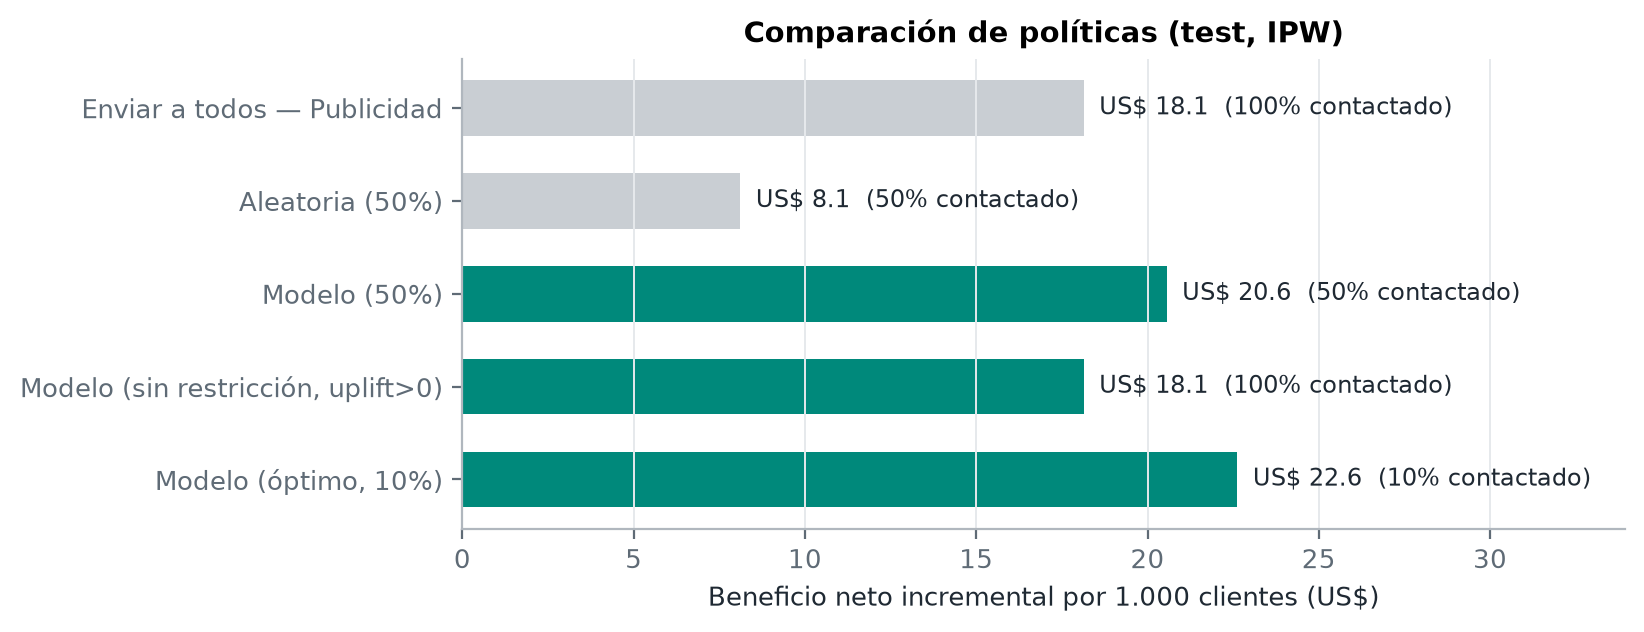

In [5]:
rank = list(cfg.business['values'])[0] if cfg.business['values'] else cfg.primary_outcome
display(pd.read_csv(cfg.tables_dir / f'policy_benchmark_{rank}.csv'))
show('budget_curves')
show('policy_benchmark')

## 5. Despliegue: scoring vía API

In [6]:
from fastapi.testclient import TestClient
from api.main import app
from uplift.data import load_split
client = TestClient(app)
cust = load_split('test', cfg)[cfg.raw_features].head(2).to_dict(orient='records')
client.post(f'/{cfg.name}/predict', json={'customers': cust}).json()

{'dataset': 'criteo',
 'model_version': '2.0.0',
 'objective': 'profit',
 'predictions': [{'uplift': {'visit': {'ads': -1.3746653253195705e-05},
    'conversion': {'ads': 9.352531701379107e-06}},
   'recommended_treatment': 'no_ads',
   'expected_value': -0.004812949365972418,
   'expected_profit_usd': -0.004812949365972418},
  {'uplift': {'visit': {'ads': 0.007387889075693779},
    'conversion': {'ads': 0.0005609143996569877}},
   'recommended_treatment': 'ads',
   'expected_value': 0.006218287993139753,
   'expected_profit_usd': 0.006218287993139753}]}

## 6. Monitoreo de drift (ventanas simuladas)

In [7]:
from uplift import monitoring
monitoring.run(cfg)

  W1: PSI máx=0.000 alerta=False


  W2: PSI máx=0.000 alerta=False


  W3: PSI máx=0.000 alerta=False


  W4: PSI máx=0.000 alerta=False


  W5 (drift): PSI máx=0.417 alerta=True


,window,n,psi_f0,psi_f1,psi_f2,psi_f3,psi_f4,psi_f5,psi_f6,psi_f7,...,psi_f10,psi_f11,psi_max,psi_prediction,mean_uplift_primary,share_recommended_contact,qini_rel_visit_ads,qini_rel_conversion_ads,evidently_share_drifted,alert
0,W1,150000,0.0001,0.0000,0.0000,0.0000,0.0000,0.0000,0.0001,0.0000,...,0.0000,0.0000,0.0001,0.0000,0.0071,0.2108,0.2934,0.4019,0.0000,False
1,W2,150000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0001,0.0070,0.2093,0.3919,0.4852,0.0000,False
2,W3,150000,0.0001,0.0000,0.0001,0.0000,0.0000,0.0000,0.0001,0.0000,...,0.0000,0.0000,0.0001,0.0001,0.0070,0.2087,0.3723,0.4565,0.0000,False
3,W4,150000,0.0001,0.0000,0.0001,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0001,0.0002,0.0070,0.2096,0.2925,0.4079,0.0000,False
4,W5 (drift),150000,0.4170,0.0000,0.0094,0.0050,0.0000,0.0000,0.0224,0.0000,...,0.0000,0.0000,0.4170,0.1355,0.0072,0.3129,0.1749,0.4408,0.4167,True
